In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

print("Digital Twin libraries imported successfully.")

Digital Twin libraries imported successfully.


In [2]:
DATA_PATH = "../data/processed/ml_dataset.csv"

df = pd.read_csv(DATA_PATH)

df["timestamp"] = pd.to_datetime(df["timestamp"])

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("Patients:", df["Patient"].nunique())

Dataset loaded successfully.
Dataset shape: (65499, 21)
Patients: 6


In [3]:
MODEL_PATH = "../models/improved_random_forest_glucose_model.pkl"
FEATURE_PATH = "../models/feature_columns.pkl"

model = joblib.load(MODEL_PATH)
feature_columns = joblib.load(FEATURE_PATH)

print("Model loaded successfully.")
print("Number of expected features:", len(feature_columns))
print("Features:", feature_columns)

Model loaded successfully.
Number of expected features: 18
Features: ['glucose_value', 'glucose_lag_1', 'glucose_lag_2', 'glucose_lag_3', 'glucose_lag_6', 'glucose_change_5min', 'glucose_change_15min', 'meal_carbs', 'bolus_dose', 'basal_value', 'temp_basal_value', 'exercise_duration', 'exercise_intensity', 'sleep_duration_hours', 'sleep_quality', 'finger_stick_value', 'hour', 'day_of_week']


In [4]:
# Select a patient with meaningful lifestyle information

candidates = df[
    (df["meal_carbs"] > 0) |
    (df["exercise_duration"] > 0) |
    (df["sleep_duration_hours"] > 0)
].copy()

sample = candidates.sort_values(
    by="timestamp"
).iloc[-1].copy()

print("Virtual patient created.")
print("---------------------------------------")
print("Patient:", sample["Patient"])
print("Timestamp:", sample["timestamp"])
print("Current glucose:", sample["glucose_value"], "mg/dL")
print("Meal carbs:", sample["meal_carbs"], "g")
print("Exercise duration:", sample["exercise_duration"], "minutes")
print("Exercise intensity:", sample["exercise_intensity"])
print("Sleep duration:", sample["sleep_duration_hours"], "hours")
print("Sleep quality:", sample["sleep_quality"])
print("Bolus dose:", sample["bolus_dose"])

Virtual patient created.
---------------------------------------
Patient: 540-ws-training
Timestamp: 2027-07-03 23:26:44
Current glucose: 267 mg/dL
Meal carbs: 100.0 g
Exercise duration: 0.0 minutes
Exercise intensity: 0.0
Sleep duration: 0.0 hours
Sleep quality: 0.0
Bolus dose: 0.9


In [5]:
def predict_glucose(state):
    X = pd.DataFrame([state])

    X = X[feature_columns]

    prediction = model.predict(X)[0]

    return prediction


baseline_prediction = predict_glucose(sample)

print("Current Digital Twin prediction")
print("---------------------------------------")
print(
    "Predicted glucose after 30 minutes:",
    round(baseline_prediction, 2),
    "mg/dL"
)

Current Digital Twin prediction
---------------------------------------
Predicted glucose after 30 minutes: 266.89 mg/dL


In [6]:
# Create copies of the current patient state

current = sample.copy()

reduced_carbs = sample.copy()
reduced_carbs["meal_carbs"] = max(
    0,
    sample["meal_carbs"] * 0.5
)

increased_exercise = sample.copy()

if sample["exercise_duration"] > 0:
    increased_exercise["exercise_duration"] = (
        sample["exercise_duration"] + 20
    )
else:
    increased_exercise["exercise_duration"] = 20

increased_exercise["exercise_intensity"] = max(
    sample["exercise_intensity"],
    1
)

improved_sleep = sample.copy()

improved_sleep["sleep_duration_hours"] = max(
    sample["sleep_duration_hours"],
    8
)

improved_sleep["sleep_quality"] = max(
    sample["sleep_quality"],
    4
)

print("Lifestyle scenarios created successfully.")

Lifestyle scenarios created successfully.


In [7]:
scenarios = {
    "Current Lifestyle": current,
    "Reduced Carbohydrates": reduced_carbs,
    "Increased Exercise": increased_exercise,
    "Improved Sleep": improved_sleep
}

scenario_results = []

for scenario_name, scenario_state in scenarios.items():

    prediction = predict_glucose(scenario_state)

    scenario_results.append({
        "Scenario": scenario_name,
        "Predicted_Glucose_30min": prediction
    })

scenario_results = pd.DataFrame(scenario_results)

print(scenario_results)

                Scenario  Predicted_Glucose_30min
0      Current Lifestyle               266.889672
1  Reduced Carbohydrates               263.928316
2     Increased Exercise               266.889672
3         Improved Sleep               269.640017


In [8]:
baseline = scenario_results.loc[
    scenario_results["Scenario"] == "Current Lifestyle",
    "Predicted_Glucose_30min"
].iloc[0]

scenario_results["Change_from_Baseline"] = (
    scenario_results["Predicted_Glucose_30min"] - baseline
)

print("Scenario comparison")
print("---------------------------------------")

display(
    scenario_results.round(2)
)

Scenario comparison
---------------------------------------


,Scenario,Predicted_Glucose_30min,Change_from_Baseline
0,Current Lifestyle,266.89,0.00
1,Reduced Carbohydrates,263.93,-2.96
2,Increased Exercise,266.89,0.00
3,Improved Sleep,269.64,2.75


In [9]:
MEANINGFUL_IMPROVEMENT = 2.0

alternative_results = scenario_results[
    scenario_results["Scenario"] != "Current Lifestyle"
].copy()

# For this project, lower predicted glucose is considered an improvement
alternative_results["Improvement"] = (
    baseline -
    alternative_results["Predicted_Glucose_30min"]
)

meaningful = alternative_results[
    alternative_results["Improvement"] >= MEANINGFUL_IMPROVEMENT
]

if len(meaningful) > 0:

    best_row = meaningful.loc[
        meaningful["Improvement"].idxmax()
    ]

    best_scenario = best_row["Scenario"]
    best_prediction = best_row["Predicted_Glucose_30min"]
    best_improvement = best_row["Improvement"]

    decision = (
        f"Recommended scenario: {best_scenario}"
    )

else:

    best_scenario = "Current Lifestyle"
    best_prediction = baseline
    best_improvement = 0

    decision = (
        "No scenario produced a meaningful simulated improvement. "
        "Maintain current lifestyle state."
    )

print("DIGITAL TWIN DECISION")
print("---------------------------------------")
print("Baseline prediction:", round(baseline, 2), "mg/dL")
print("Best scenario:", best_scenario)
print("Best prediction:", round(best_prediction, 2), "mg/dL")
print("Improvement:", round(best_improvement, 2), "mg/dL")
print("Decision:", decision)

DIGITAL TWIN DECISION
---------------------------------------
Baseline prediction: 266.89 mg/dL
Best scenario: Reduced Carbohydrates
Best prediction: 263.93 mg/dL
Improvement: 2.96 mg/dL
Decision: Recommended scenario: Reduced Carbohydrates


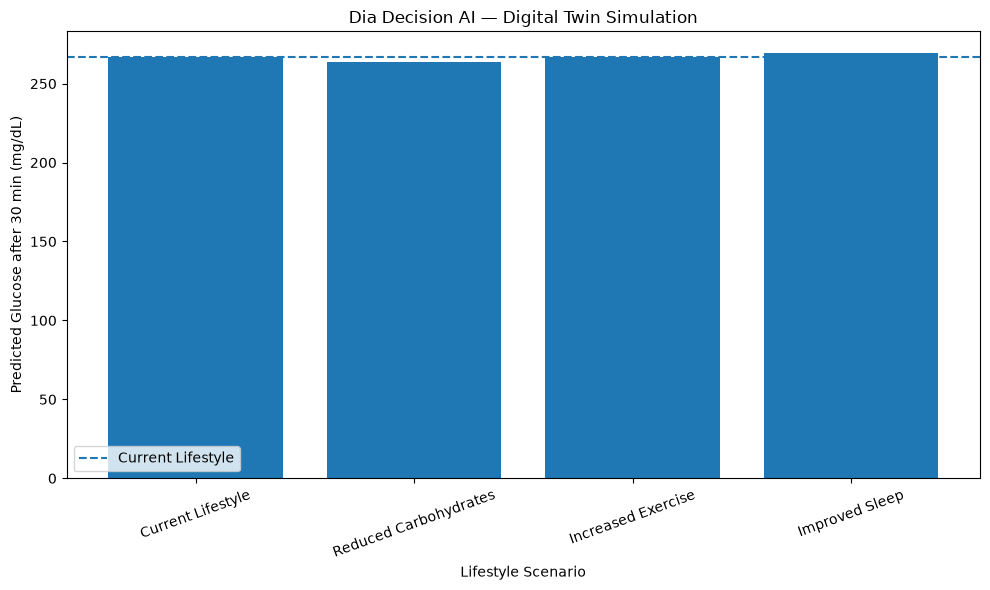

In [10]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    scenario_results["Scenario"],
    scenario_results["Predicted_Glucose_30min"]
)

plt.axhline(
    baseline,
    linestyle="--",
    label="Current Lifestyle"
)

plt.xlabel("Lifestyle Scenario")
plt.ylabel("Predicted Glucose after 30 min (mg/dL)")
plt.title("Dia Decision AI — Digital Twin Simulation")

plt.xticks(rotation=20)
plt.legend()

plt.tight_layout()
plt.show()

In [11]:
print("=" * 60)
print("        DIA DECISION AI — DIGITAL TWIN")
print("=" * 60)

print()

print("PATIENT")
print("---------------------------------------")
print("Patient:", sample["Patient"])
print("Timestamp:", sample["timestamp"])

print()

print("CURRENT STATE")
print("---------------------------------------")
print("Current glucose:", sample["glucose_value"], "mg/dL")
print("Meal carbohydrates:", sample["meal_carbs"], "g")
print("Exercise:", sample["exercise_duration"], "minutes")
print("Sleep:", sample["sleep_duration_hours"], "hours")
print("Sleep quality:", sample["sleep_quality"])

print()

print("SIMULATION RESULTS")
print("---------------------------------------")

for _, row in scenario_results.iterrows():

    print(
        f"{row['Scenario']}: "
        f"{row['Predicted_Glucose_30min']:.2f} mg/dL"
    )

print()

print("FINAL DECISION")
print("---------------------------------------")
print(decision)

print()

print("=" * 60)
print("Digital Twin simulation completed successfully.")
print("=" * 60)

        DIA DECISION AI — DIGITAL TWIN

PATIENT
---------------------------------------
Patient: 540-ws-training
Timestamp: 2027-07-03 23:26:44

CURRENT STATE
---------------------------------------
Current glucose: 267 mg/dL
Meal carbohydrates: 100.0 g
Exercise: 0.0 minutes
Sleep: 0.0 hours
Sleep quality: 0.0

SIMULATION RESULTS
---------------------------------------
Current Lifestyle: 266.89 mg/dL
Reduced Carbohydrates: 263.93 mg/dL
Increased Exercise: 266.89 mg/dL
Improved Sleep: 269.64 mg/dL

FINAL DECISION
---------------------------------------
Recommended scenario: Reduced Carbohydrates

Digital Twin simulation completed successfully.
